<div style="background:#1f2933;color:#ffffff;padding:28px 32px;border-radius:14px">
<div style="font-size:12px;letter-spacing:3px;color:#f6c39a">HR ANALYTICS &nbsp;·&nbsp; IBM SAMPLE DATASET &nbsp;·&nbsp; 1,470 EMPLOYEES</div>
<div style="font-size:30px;font-weight:700;margin:8px 0 6px">👥 IBM HR Analytics: Employee Attrition Prevention Strategy</div>
<div style="font-size:15px;color:#dfe5ec">Who leaves, why, how well we can predict it, and what retention measures would be worth</div>
</div>


<div style="background:#eaf6f4;border-left:5px solid #2a9d8f;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#2a9d8f">👤 About this notebook</b><br>I made this analysis as part of my <b>data analytics portfolio</b>. It takes an HR question from raw data to recommendations: data checks, segmentation, statistical tests with effect sizes, a predictive model evaluated against a baseline, and a business case whose assumptions are explicit.<br><br><b>Mihail Deligrozev</b> · Data analyst · Python · SQL · Power BI</div>

<div style="background:#eef4ff;border-left:5px solid #2a6fdb;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#2a6fdb">📌 Note</b><br>The <a href="https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset">IBM HR Analytics Employee Attrition & Performance</a> dataset is a <b>fictional dataset created by IBM data scientists</b>, not real IBM records. It is a single snapshot: it shows who left, not when, so every rate here is a share of this workforce, not an annual rate.</div>

## ⭐ Summary

<div style="background:#eef4ff;border-radius:10px;padding:14px 20px;line-height:1.7">
📉 <b>16.1% of employees left</b> (237 of 1,470).<br>
⏰ <b>Overtime is the strongest single factor.</b> 30.5% attrition with overtime vs 10.4% without (2.9x).<br>
🎯 <b>Risk is concentrated.</b> Sales Representatives (39.8%), employees in their first 2 years (29.8%), under-25s (35.8%) and the lowest income band (28.6%).<br>
💰 <b>Leavers earn less.</b> Median monthly income $3,202 vs $5,204 for those who stayed.<br>
🤖 <b>A simple model ranks risk well.</b> Logistic regression reaches test AUC <b>0.82</b> (random forest 0.77); flagging the top 20% of risk scores finds 62% of leavers.<br>
⚠️ <b>Accuracy is the wrong yardstick.</b> Predicting "everyone stays" is already 83.9% accurate, so the model is judged on AUC, precision and recall.
</div>

## 🧭 Contents

| | Section | Question it answers |
|---|---|---|
| ⚙️ | [1. Setup](#s1) | Libraries, helpers, data path |
| 📊 | [2. Data loading and quality](#s2) | Is the data complete and clean? |
| 🧹 | [3. Preprocessing and segments](#s3) | Which age, income and tenure bands, and do they differ? |
| 📈 | [4. Overall attrition](#s4) | How big is the problem? |
| 🏢 | [5. Departments and job roles](#s5) | Where is attrition concentrated? |
| 👥 | [6. Demographics, pay and satisfaction](#s6) | Who leaves? |
| 🔑 | [7. Key factor tests](#s7) | Which factors matter, and how strongly? |
| 📉 | [8. Correlations](#s8) | How do numeric features relate to leaving? |
| 🤖 | [9. Predictive model](#s9) | Can we flag at-risk employees in advance? |
| 💼 | [10. Business case](#s10) | What would retention measures be worth? |
| 🏁 | [11. Findings, roadmap and limits](#s11) | What to do, and what not to over-claim |

**How to read it:** 🧠 purple boxes explain *why* a step is done, 💡 blue boxes give the computed insight, ⚠️ orange boxes flag caveats.
Orange in charts means **left** or **above the average attrition rate**; teal means **stayed**. Cells starting with `# Parameters` hold assumptions you can change.

<a id="s1"></a>
## ⚙️ 1. Setup

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>Helper functions (chart style, confidence intervals, effect sizes, note boxes) live in <code>hr_utils.py</code>, so the notebook shows the analysis. Files are <b>found</b> rather than hard-coded, so it runs on Kaggle and locally without edits.</div>

In [1]:
# Make hr_utils.py importable: on Kaggle it can be attached as a dataset or model, locally it sits next to the notebook
import glob
import os
import sys

found = sorted(glob.glob('/kaggle/input/**/hr_utils.py', recursive=True))
if found:
    sys.path.insert(0, os.path.dirname(found[-1]))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import warnings

from hr_utils import (BLUE, GRID, INK, LEFT, MUTED, PALE, PURPLE, STATUS_COLORS, STATUS_ORDER, STAYED, callout, chi2_test,
                      fmt_p, gains_curve, lollipop, metrics_at, pct, rate_bars, rate_table, set_style, show,
                      threshold_for_recall, titles, wilson)

warnings.filterwarnings('ignore')
set_style()

# Find Attrition.csv: attached Kaggle dataset first, then the notebook folder
hits = sorted(glob.glob('/kaggle/input/**/*ttrition*.csv', recursive=True))
DATA_FILE = hits[0] if hits else 'Attrition.csv'
print('Reading', DATA_FILE)

Reading Attrition.csv


<a id="s2"></a>
## 📊 2. Data loading and quality

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>Before any rate is computed: are there gaps, duplicates or columns that carry no information? One compact profile replaces separate checks, so problems are visible at a glance.</div>

In [2]:
df = pd.read_csv(DATA_FILE)
constant_cols = [c for c in df.columns if df[c].nunique() == 1]

profile = pd.Series({
    'Employees (rows)': f'{len(df):,}',
    'Columns': df.shape[1],
    'Numeric / text columns': f'{df.select_dtypes("number").shape[1]} / {df.select_dtypes(exclude="number").shape[1]}',
    'Missing values': int(df.isna().sum().sum()),
    'Duplicate rows': int(df.duplicated().sum()),
    'Duplicate employee numbers': int(df['EmployeeNumber'].duplicated().sum()),
    'Constant columns': ', '.join(constant_cols),
    'Job roles / departments': f'{df["JobRole"].nunique()} / {df["Department"].nunique()}',
}, name='value').to_frame()
profile

,value
Employees (rows),"1,470"
Columns,35
Numeric / text columns,26 / 9
Missing values,0
Duplicate rows,0
Duplicate employee numbers,0
Constant columns,"EmployeeCount, Over18, StandardHours"
Job roles / departments,9 / 3


In [3]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [4]:
callout(f'The data is complete: **{int(df.isna().sum().sum())} missing values** and **{int(df.duplicated().sum())} duplicates**. '
        f'**{len(constant_cols)} columns** hold a single value ({", ".join(constant_cols)}) and carry no information, so they are dropped. '
        f'`EmployeeNumber` is an ID and is kept out of the analysis.')

<a id="s3"></a>
## 🧹 3. Preprocessing and segments

Three bands turn continuous variables into groups HR can act on. Each band is checked with a chi-square test and **Cramér's V**, an effect size from 0 (no link) to 1, where about 0.1 is small, 0.3 medium and 0.5 large.

| Band | Groups | Career-stage logic |
|---|---|---|
| Age | 18-25, 26-35, 36-45, 46-55, 56-60 | First jobs, early career, mid-career, late career, pre-retirement |
| Monthly income | Low (<$3k), Medium ($3-6k), High ($6-10k), Very high ($10k+) | Roughly the quartiles of the income distribution |
| Tenure | 0-2, 3-5, 6-10, 10+ years | Onboarding, establishing, established, long-serving |

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>A p-value alone only says a difference exists; with 1,470 people even small differences are "significant". Cramér's V says how large it is.</div>

In [5]:
data = df.drop(columns=constant_cols + ['EmployeeNumber']).copy()
data['left'] = (data['Attrition'] == 'Yes').astype(int)                      # 1 = left, 0 = stayed
data['status'] = data['Attrition'].map({'Yes': 'Left', 'No': 'Stayed'})        # readable label for charts

data['AgeGroup'] = pd.cut(data['Age'], bins=[17, 25, 35, 45, 55, 60],
                          labels=['18-25', '26-35', '36-45', '46-55', '56-60'])
data['IncomeGroup'] = pd.cut(data['MonthlyIncome'], bins=[0, 3000, 6000, 10000, 20000],
                             labels=['Low', 'Medium', 'High', 'Very high'])
data['TenureBand'] = pd.cut(data['YearsAtCompany'], bins=[-1, 2, 5, 10, 100],
                            labels=['0-2 yrs', '3-5 yrs', '6-10 yrs', '10+ yrs'])

assert data[['AgeGroup', 'IncomeGroup', 'TenureBand']].notna().all().all(), 'a value fell outside the bands'
overall = data['left'].mean()

bands = {'AgeGroup': 'Age group', 'IncomeGroup': 'Monthly income', 'TenureBand': 'Years at company'}
band_tests = pd.DataFrame({label: chi2_test(data, col) for col, label in bands.items()}).T
band_tests['p'] = band_tests['p'].map(fmt_p)
band_tests[['chi2', 'p', 'cramers_v']].round(3)

,chi2,p,cramers_v
Age group,59.439,< 0.001,0.201
Monthly income,64.287,< 0.001,0.209
Years at company,65.695,< 0.001,0.211


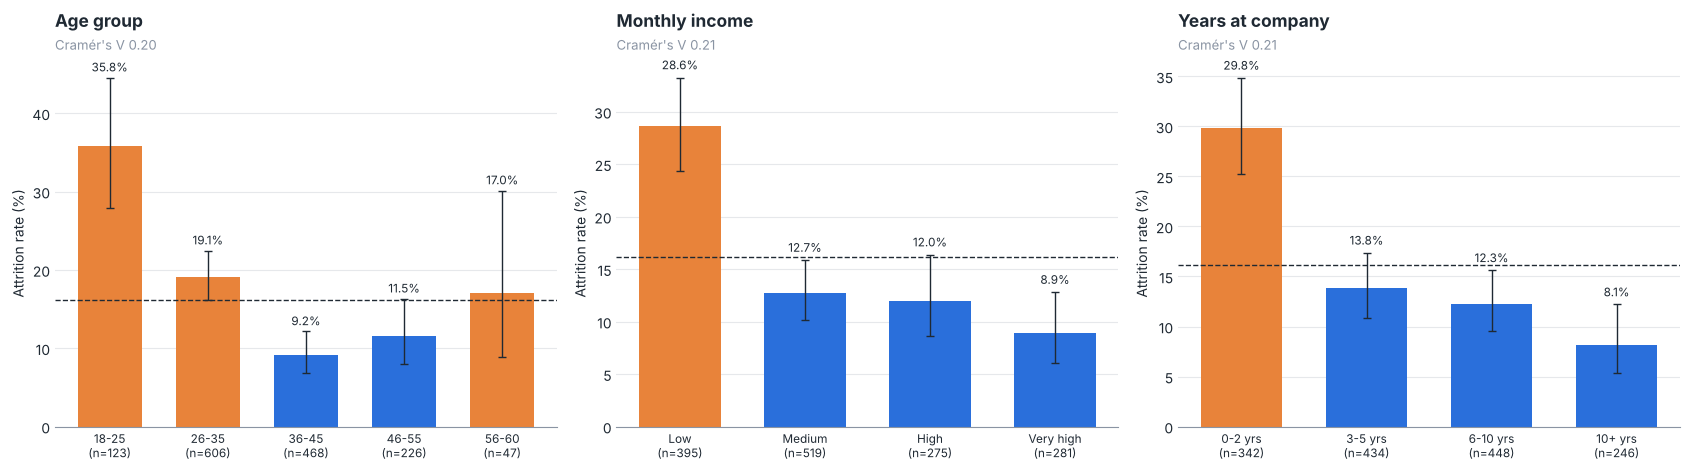

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for a, (col, label) in zip(ax, bands.items()):
    g = rate_table(data, col)
    rate_bars(a, g, overall, label, f"Cramér's V {chi2_test(data, col)['cramers_v']:.2f}")
plt.tight_layout()
show(fig, 'fig01_attrition_by_band')

age_g, inc_g, ten_g = (rate_table(data, c) for c in bands)
callout(f'Attrition falls with age, pay and tenure. It is highest for **18-25 year olds ({pct(age_g["rate"].max())})**, the '
        f'**lowest income band ({pct(inc_g.loc["Low", "rate"])})** and employees in their **first 2 years ({pct(ten_g.loc["0-2 yrs", "rate"])})**, '
        f'against {pct(overall)} overall. All three bands differ significantly (p < 0.001) with small-to-medium effect sizes. '
        'The 56-60 group is small, so its rate has a wide interval.')

<a id="s4"></a>
## 📈 4. Overall attrition

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>The headline rate sets the scale. Translating it into money makes it concrete, but the cost per leaver is an <b>assumption</b>, so it lives in a parameter cell where it can be changed.</div>

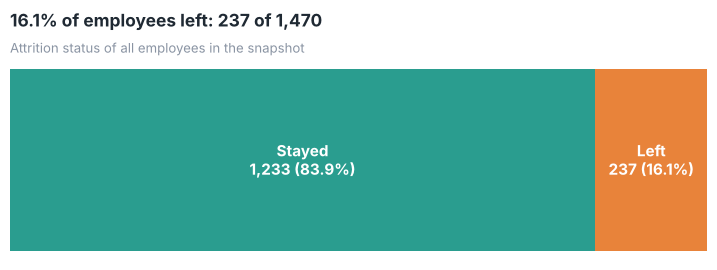

In [7]:
# Parameters
COST_PER_LEAVER = 50_000      # assumed replacement cost per employee who leaves (recruiting, training, lost productivity)

n_left = int(data['left'].sum())
counts = data['status'].value_counts().reindex(STATUS_ORDER)

fig, ax = plt.subplots(figsize=(9, 2.6))
left_edge = 0
for status in STATUS_ORDER:
    ax.barh(0, counts[status], left=left_edge, color=STATUS_COLORS[status], height=0.55)
    ax.text(left_edge + counts[status] / 2, 0, f'{status}\n{counts[status]:,} ({pct(counts[status] / len(data))})',
            ha='center', va='center', color='white', fontsize=11, fontweight='bold')
    left_edge += counts[status]
ax.set_xlim(0, len(data))
ax.axis('off')
titles(ax, f'{pct(overall)} of employees left: {n_left} of {len(data):,}', 'Attrition status of all employees in the snapshot')
show(fig, 'fig02_overall_attrition')

callout(f'**{n_left} employees ({pct(overall)})** left. At an assumed **${COST_PER_LEAVER:,}** per leaver, that is about '
        f'**${n_left * COST_PER_LEAVER / 1e6:.1f}M** in replacement costs for this workforce, and each leaver prevented is worth about ${COST_PER_LEAVER:,}.')
callout('The data has no dates, so this is not an annual rate and cannot be compared directly with published yearly turnover benchmarks. '
        'The cost per leaver is an assumption: published estimates range from a fraction of a year\'s salary to more than one.', 'caution')

<a id="s5"></a>
## 🏢 5. Departments and job roles

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>Retention budgets are allocated by team. The 95% intervals show which differences are reliable: a role with 50 people can swing several points by chance.</div>

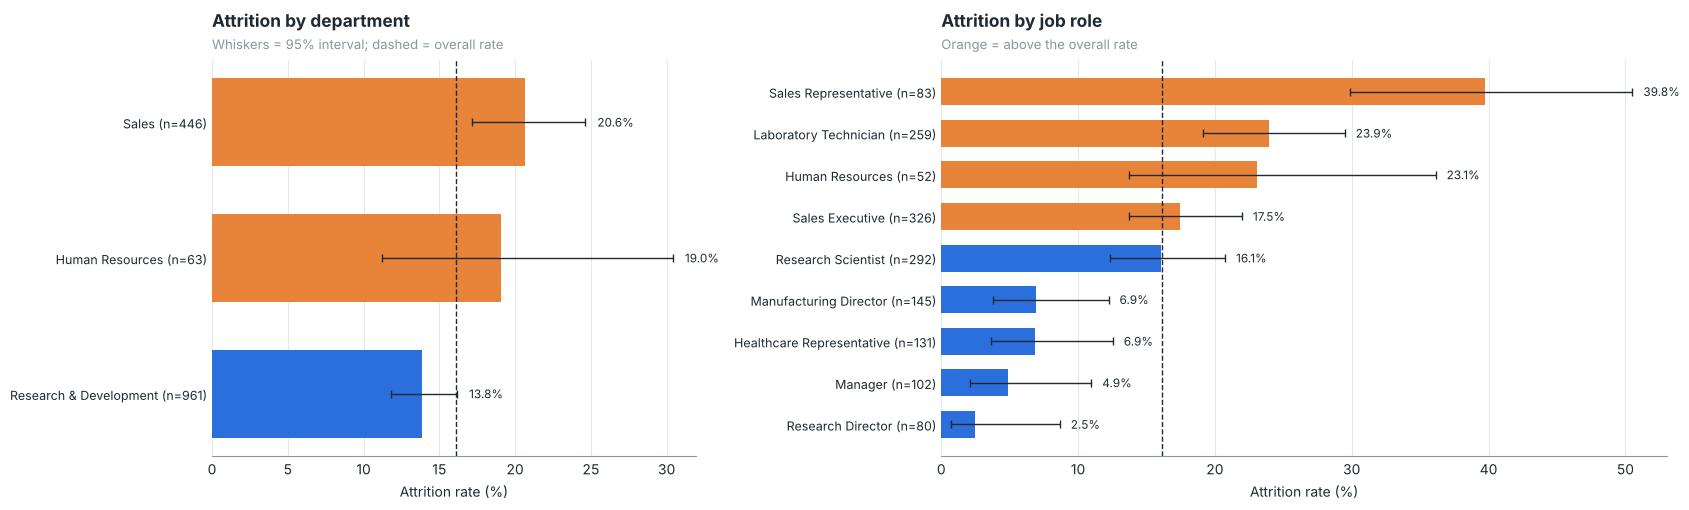

,employees,left,attrition %
JobRole,,,
Sales Representative,83,33,39.800
Laboratory Technician,259,62,23.900
Human Resources,52,12,23.100
Sales Executive,326,57,17.500
Research Scientist,292,47,16.100
Manufacturing Director,145,10,6.900
Healthcare Representative,131,9,6.900
Manager,102,5,4.900
Research Director,80,2,2.500


In [8]:
dept = rate_table(data, 'Department').sort_values('rate', ascending=False)
role = rate_table(data, 'JobRole').sort_values('rate', ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(17, 5.2), gridspec_kw={'width_ratios': [1, 1.5]})
rate_bars(ax[0], dept, overall, 'Attrition by department', 'Whiskers = 95% interval; dashed = overall rate', horizontal=True)
rate_bars(ax[1], role, overall, 'Attrition by job role', 'Orange = above the overall rate', horizontal=True)
plt.tight_layout()
show(fig, 'fig03_department_and_role')

(role[['employees', 'left', 'rate']].assign(rate=lambda t: (t['rate'] * 100).round(1))
 .rename(columns={'rate': 'attrition %'}))

In [9]:
top_role, low_role = role.index[0], role.index[-1]
callout(f'**{dept.index[0]}** has the highest department rate ({pct(dept["rate"].iloc[0])}, {dept["rate"].iloc[0] / overall:.2f}x the average). '
        f'By role, **{top_role}s** stand out at **{pct(role.loc[top_role, "rate"])}** ({role.loc[top_role, "left"]} of {role.loc[top_role, "employees"]}), '
        f'followed by Laboratory Technicians ({pct(role.loc["Laboratory Technician", "rate"])}) and Human Resources ({pct(role.loc["Human Resources", "rate"])}). '
        f'Senior roles are the most stable: {low_role}s {pct(role.loc[low_role, "rate"])}, Managers {pct(role.loc["Manager", "rate"])}.')
callout('Human Resources has only 52 people in the HR role and 63 in the department, so its rate has a wide interval; '
        'treat it as a signal to watch rather than a firm finding.', 'caution')

<a id="s6"></a>
## 👥 6. Demographics, pay and satisfaction

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>Income is heavily skewed (a few high earners pull the mean up), so groups are compared with <b>medians</b> and the <b>Mann-Whitney test</b>, which does not assume a normal distribution. Charts use the same colours throughout: teal = stayed, orange = left.</div>

In [10]:
rows = []
for col, label in [('Age', 'Age (years)'), ('MonthlyIncome', 'Monthly income ($)'), ('YearsAtCompany', 'Years at company'),
                   ('TotalWorkingYears', 'Total working years')]:
    a, b = data.loc[data['left'] == 1, col], data.loc[data['left'] == 0, col]
    u, p = mannwhitneyu(a, b)
    rows.append({'feature': label, 'median left': a.median(), 'median stayed': b.median(),
                 'mean left': a.mean(), 'mean stayed': b.mean(), 'p (Mann-Whitney)': fmt_p(p),
                 'rank-biserial r': 1 - 2 * u / (len(a) * len(b))})
group_stats = pd.DataFrame(rows).set_index('feature')
group_stats.round(2)

,median left,median stayed,mean left,mean stayed,p (Mann-Whitney),rank-biserial r
feature,,,,,,
Age (years),32.000,36.000,33.610,37.560,< 0.001,0.270
Monthly income ($),"3,202.000","5,204.000","4,787.090","6,832.740",< 0.001,0.310
Years at company,3.000,6.000,5.130,7.370,< 0.001,0.300
Total working years,7.000,10.000,8.240,11.860,< 0.001,0.310


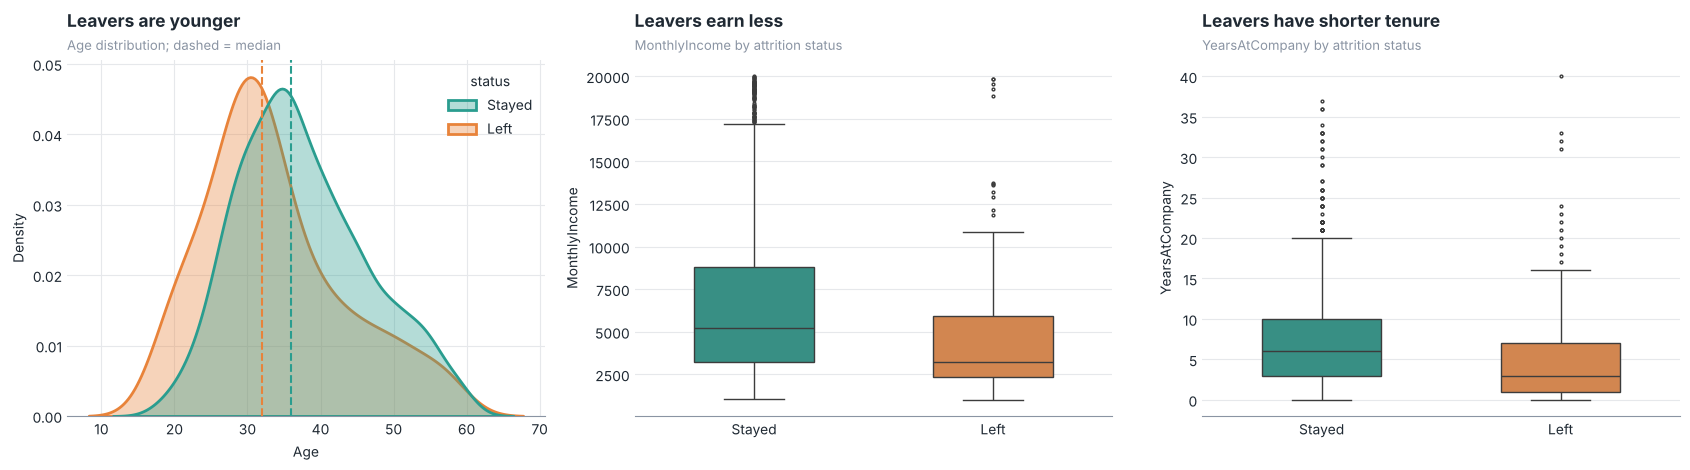

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
sns.kdeplot(data=data, x='Age', hue='status', hue_order=STATUS_ORDER, palette=STATUS_COLORS, fill=True, common_norm=False,
            alpha=0.35, linewidth=2, ax=ax[0])
for status in STATUS_ORDER:
    ax[0].axvline(data.loc[data['status'] == status, 'Age'].median(), color=STATUS_COLORS[status], ls='--', lw=1.5)
titles(ax[0], 'Leavers are younger', 'Age distribution; dashed = median')
for a, col, title in [(ax[1], 'MonthlyIncome', 'Leavers earn less'), (ax[2], 'YearsAtCompany', 'Leavers have shorter tenure')]:
    sns.boxplot(data=data, x='status', y=col, order=STATUS_ORDER, palette=STATUS_COLORS, width=0.5, fliersize=2, ax=a)
    a.set_xlabel('')
    a.grid(axis='x', visible=False)
    titles(a, title, f'{col} by attrition status')
plt.tight_layout()
show(fig, 'fig04_age_income_tenure')

inc = group_stats.loc['Monthly income ($)']
age = group_stats.loc['Age (years)']
callout(f'Leavers are younger (median **{age["median left"]:.0f}** vs **{age["median stayed"]:.0f}** years) and earn less: median monthly income '
        f'**${inc["median left"]:,.0f}** vs **${inc["median stayed"]:,.0f}** (means ${inc["mean left"]:,.0f} vs ${inc["mean stayed"]:,.0f}, '
        f'a gap of ${inc["mean stayed"] - inc["mean left"]:,.0f}). Both differences are significant (p < 0.001). Age, pay and tenure '
        'move together, so these are partly the same story: junior people earn less and have been here less long.')

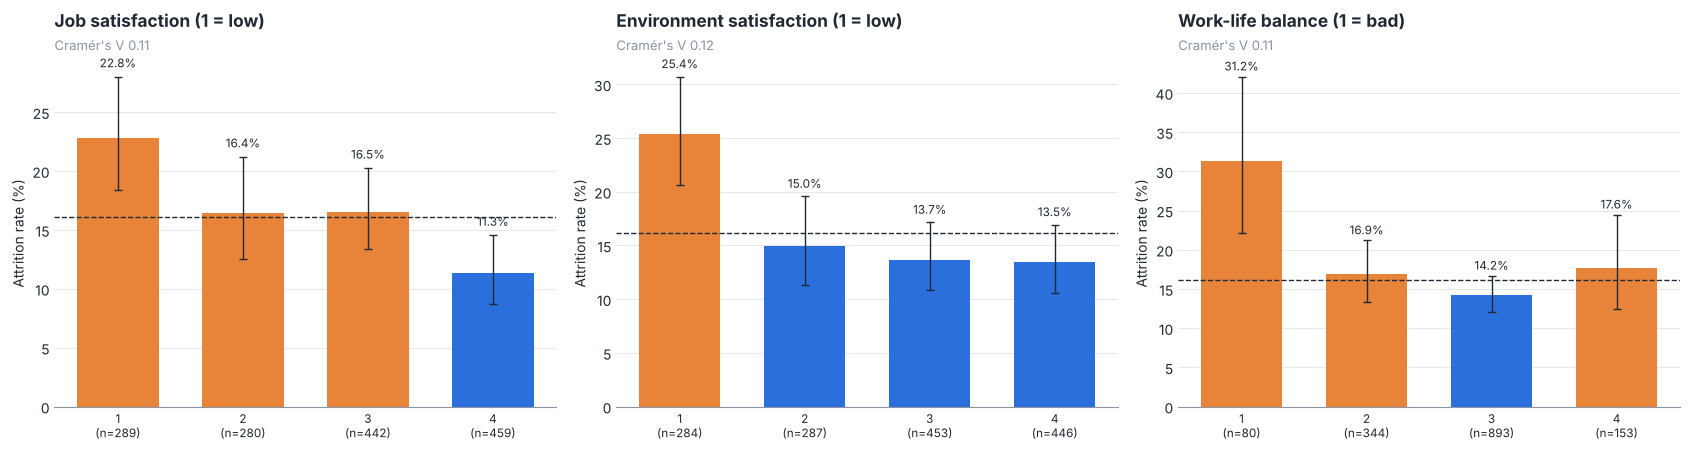

In [12]:
sat = {'JobSatisfaction': 'Job satisfaction (1 = low)', 'EnvironmentSatisfaction': 'Environment satisfaction (1 = low)',
       'WorkLifeBalance': 'Work-life balance (1 = bad)'}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a, (col, label) in zip(ax, sat.items()):
    rate_bars(a, rate_table(data, col), overall, label, f"Cramér's V {chi2_test(data, col)['cramers_v']:.2f}")
plt.tight_layout()
show(fig, 'fig05_satisfaction')

js, es, wlb = (rate_table(data, c) for c in sat)
callout(f'The lowest score on each scale goes with the highest attrition: job satisfaction 1 → **{pct(js.loc[1, "rate"])}**, '
        f'environment satisfaction 1 → **{pct(es.loc[1, "rate"])}**, work-life balance 1 → **{pct(wlb.loc[1, "rate"])}**. '
        'Above the lowest level the differences are small, so the risk sits with the clearly unhappy group rather than rising steadily.')

<a id="s7"></a>
## 🔑 7. Key factor tests

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>Testing every factor the same way, and ranking by effect size instead of p-value, shows which levers matter most. Charts show the <b>attrition rate</b> per level rather than raw counts, because counts hide rates when groups differ in size.</div>

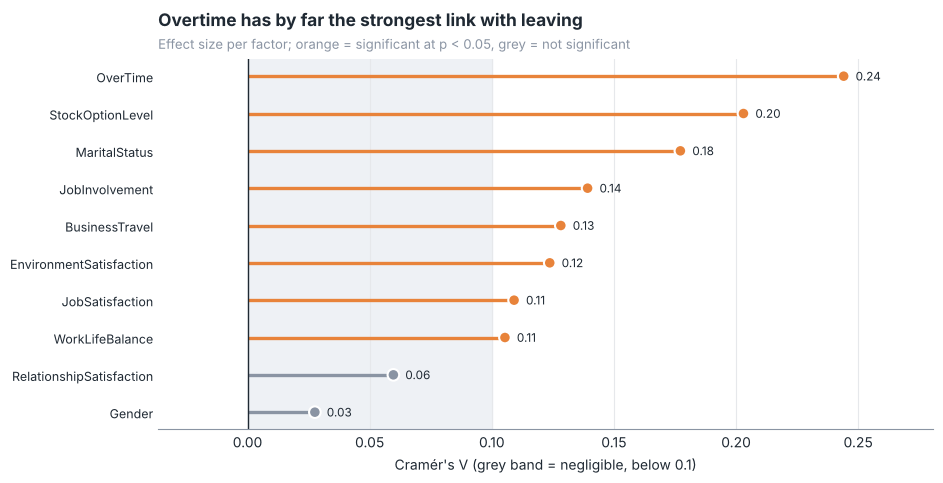

,chi2,p,cramers_v,significant
OverTime,87.564,< 0.001,0.244,yes
StockOptionLevel,60.598,< 0.001,0.203,yes
MaritalStatus,46.164,< 0.001,0.177,yes
JobInvolvement,28.492,< 0.001,0.139,yes
BusinessTravel,24.182,< 0.001,0.128,yes
EnvironmentSatisfaction,22.504,< 0.001,0.124,yes
JobSatisfaction,17.505,< 0.001,0.109,yes
WorkLifeBalance,16.325,< 0.001,0.105,yes
RelationshipSatisfaction,5.241,0.155,0.060,no
Gender,1.117,0.291,0.028,no


In [13]:
key_factors = ['OverTime', 'MaritalStatus', 'BusinessTravel', 'JobInvolvement', 'StockOptionLevel', 'JobSatisfaction',
               'EnvironmentSatisfaction', 'WorkLifeBalance', 'RelationshipSatisfaction', 'Gender']
factor_tests = (pd.DataFrame({f: chi2_test(data, f) for f in key_factors}).T
                .sort_values('cramers_v', ascending=False))
factor_tests['significant'] = np.where(factor_tests['p'] < 0.05, 'yes', 'no')
factor_tests['p'] = factor_tests['p'].map(fmt_p)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axvspan(0, 0.1, color=PALE, zorder=0)
lollipop(ax, factor_tests['cramers_v'].astype(float), center=0, fmt='{:.2f}',
         colors=[LEFT if s == 'yes' else MUTED for s in factor_tests['significant']])
ax.set_xlabel("Cramér's V (grey band = negligible, below 0.1)")
titles(ax, 'Overtime has by far the strongest link with leaving', "Effect size per factor; orange = significant at p < 0.05, grey = not significant")
show(fig, 'fig06_factor_effect_sizes')

factor_tests[['chi2', 'p', 'cramers_v', 'significant']].round(3)

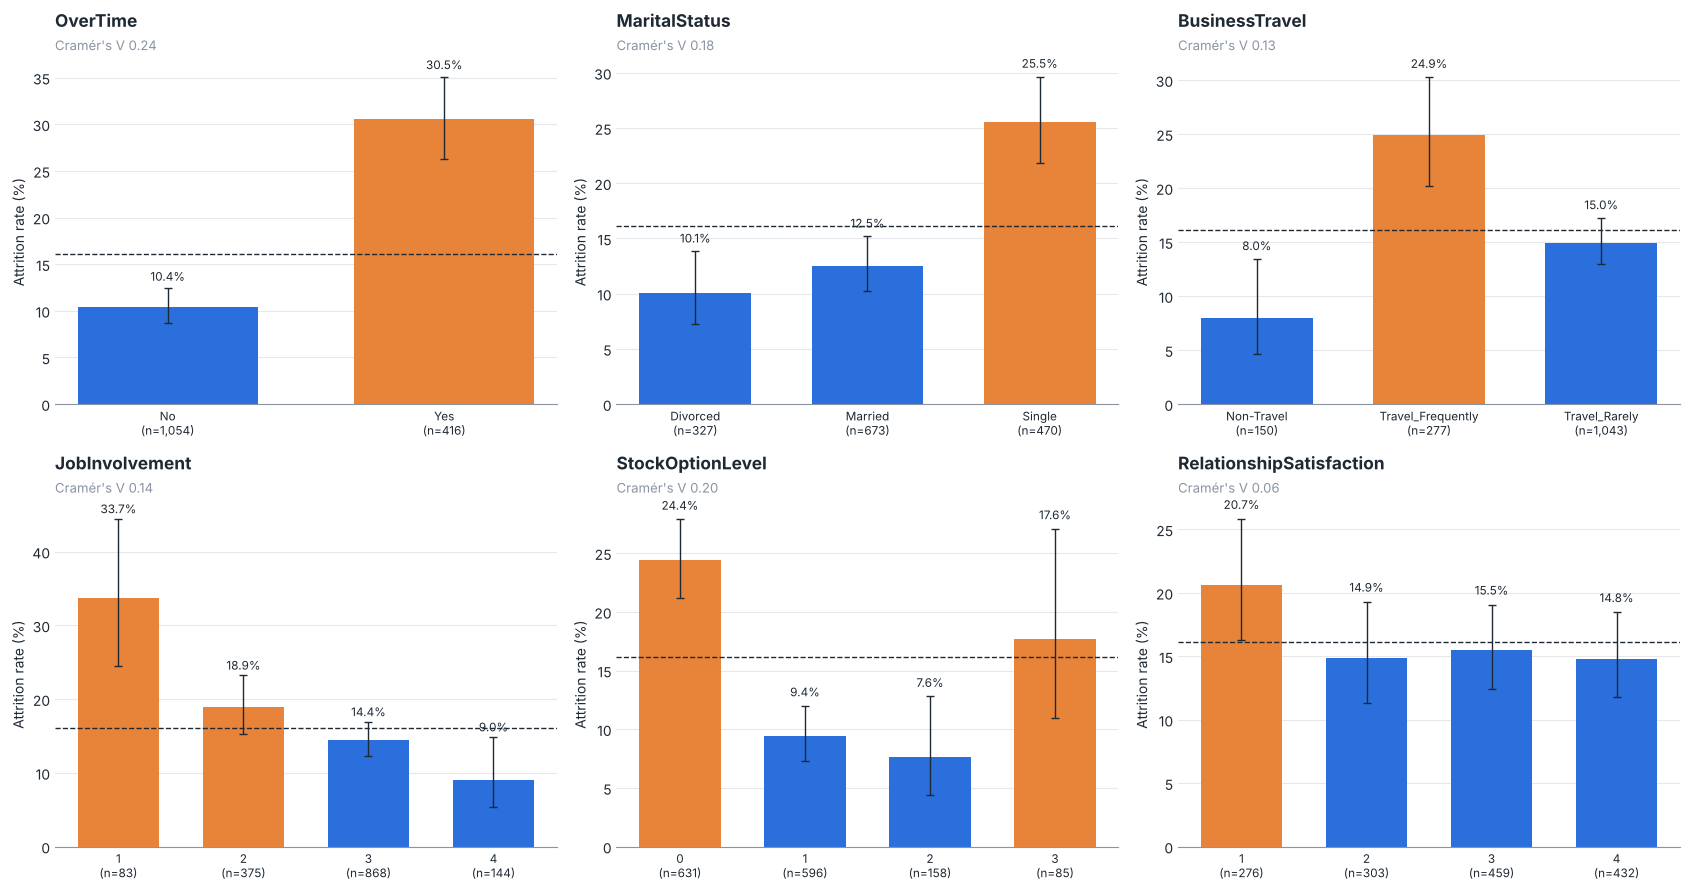

In [14]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for a, f in zip(ax.ravel(), ['OverTime', 'MaritalStatus', 'BusinessTravel', 'JobInvolvement', 'StockOptionLevel', 'RelationshipSatisfaction']):
    rate_bars(a, rate_table(data, f), overall, f, f"Cramér's V {chi2_test(data, f)['cramers_v']:.2f}")
plt.tight_layout()
show(fig, 'fig07_factor_rates')

ot = rate_table(data, 'OverTime')
ms = rate_table(data, 'MaritalStatus')
bt = rate_table(data, 'BusinessTravel')
not_sig = factor_tests.index[factor_tests['significant'] == 'no'].tolist()
callout(f'**Overtime** is the strongest single factor: **{pct(ot.loc["Yes", "rate"])}** attrition with overtime vs **{pct(ot.loc["No", "rate"])}** without '
        f'(**{ot.loc["Yes", "rate"] / ot.loc["No", "rate"]:.1f}x**), and {pct((data["OverTime"] == "Yes").mean(), 0)} of employees work overtime. '
        f'Single employees ({pct(ms.loc["Single", "rate"])}) and frequent travellers ({pct(bt.loc["Travel_Frequently", "rate"])}) are also at higher risk. '
        f'Not significant: {", ".join(not_sig)}.')

<a id="s8"></a>
## 📉 8. Correlations

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>Correlation with the 0/1 attrition flag gives one comparable number per numeric feature. It only captures straight-line links, so the band and factor charts above remain the better guide to shape.</div>

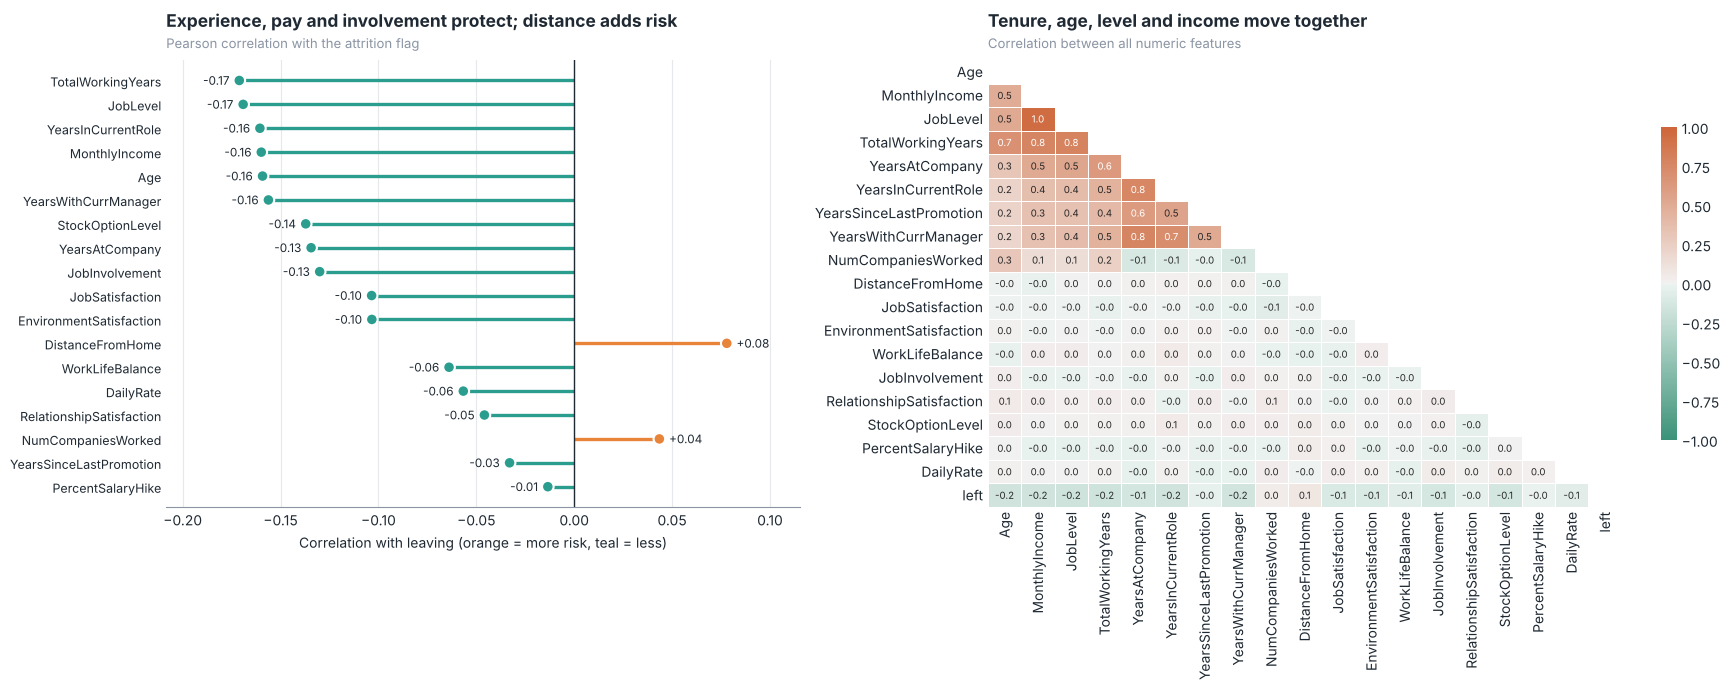

In [15]:
numeric = ['Age', 'MonthlyIncome', 'JobLevel', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole',
           'YearsSinceLastPromotion', 'YearsWithCurrManager', 'NumCompaniesWorked', 'DistanceFromHome',
           'JobSatisfaction', 'EnvironmentSatisfaction', 'WorkLifeBalance', 'JobInvolvement',
           'RelationshipSatisfaction', 'StockOptionLevel', 'PercentSalaryHike', 'DailyRate', 'left']
corr = data[numeric].corr()
with_left = corr['left'].drop('left').sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1, 1.25]})
lollipop(ax[0], with_left, center=0, fmt='{:+.2f}', colors=[LEFT if v > 0 else STAYED for v in with_left])
ax[0].set_xlabel('Correlation with leaving (orange = more risk, teal = less)')
titles(ax[0], 'Experience, pay and involvement protect; distance adds risk', 'Pearson correlation with the attrition flag')

mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap=sns.diverging_palette(160, 25, s=80, l=55, as_cmap=True), center=0, vmin=-1, vmax=1,
            annot=True, fmt='.1f', annot_kws={'fontsize': 7}, linewidths=0.5, cbar_kws={'shrink': 0.7}, ax=ax[1])
ax[1].grid(False)
titles(ax[1], 'Tenure, age, level and income move together', 'Correlation between all numeric features')
plt.tight_layout()
show(fig, 'fig08_correlations')

pos, neg = with_left[with_left > 0], with_left[with_left < 0]
callout('Strongest protective features: ' + ', '.join(f'**{k}** ({v:+.2f})' for k, v in neg.head(4).items()) +
        '. Risk features: ' + ', '.join(f'**{k}** ({v:+.2f})' for k, v in pos.head(3).items()) +
        '. All correlations are weak (|r| < 0.2), and tenure, age, job level and income are strongly correlated with each other, '
        'so they should not be read as separate causes.')

<a id="s9"></a>
## 🤖 9. Predictive model

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>Only 16% of employees left, so a model that predicts "everyone stays" is already 84% accurate and useless. Models are therefore compared on <b>AUC</b> (how well they rank leavers above stayers), with <b>5-fold cross-validation</b> on the training set because the test set holds only 71 leavers. The decision threshold is chosen on cross-validated training predictions, never on the test set, and then checked once on the test set.</div>

In [16]:
ml_features = ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel',
               'JobSatisfaction', 'MonthlyIncome', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
               'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
               'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager',
               'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus']
categorical = ['OverTime', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus']

X = pd.get_dummies(data[ml_features], columns=categorical, drop_first=True).astype(float)
y = data['left']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(f'{X.shape[1]} features after encoding · train {len(X_train):,} ({y_train.sum()} leavers) · test {len(X_test):,} ({y_test.sum()} leavers)')

42 features after encoding · train 1,029 (166 leavers) · test 441 (71 leavers)


In [17]:
models = {
    'Baseline: always "stays"': DummyClassifier(strategy='most_frequent'),
    'Random forest': RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_split=5, min_samples_leaf=2,
                                            class_weight='balanced', random_state=42, n_jobs=-1),
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(C=0.3, class_weight='balanced', max_iter=2000)),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows, test_proba = [], {}
for name, model in models.items():
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    test_proba[name] = proba
    rows.append({'model': name, 'CV AUC (mean)': cv_auc.mean(), 'CV AUC (sd)': cv_auc.std(),
                 'test AUC': roc_auc_score(y_test, proba), 'test avg precision': average_precision_score(y_test, proba),
                 'test accuracy at 0.5': ((proba >= 0.5) == y_test).mean()})
results = pd.DataFrame(rows).set_index('model')
best_name = results.drop(index='Baseline: always "stays"')['CV AUC (mean)'].idxmax()
best = models[best_name]
results.round(3)

,CV AUC (mean),CV AUC (sd),test AUC,test avg precision,test accuracy at 0.5
model,,,,,
"Baseline: always ""stays""",0.500,0.000,0.500,0.161,0.839
Random forest,0.809,0.040,0.766,0.406,0.819
Logistic regression,0.824,0.053,0.820,0.599,0.751


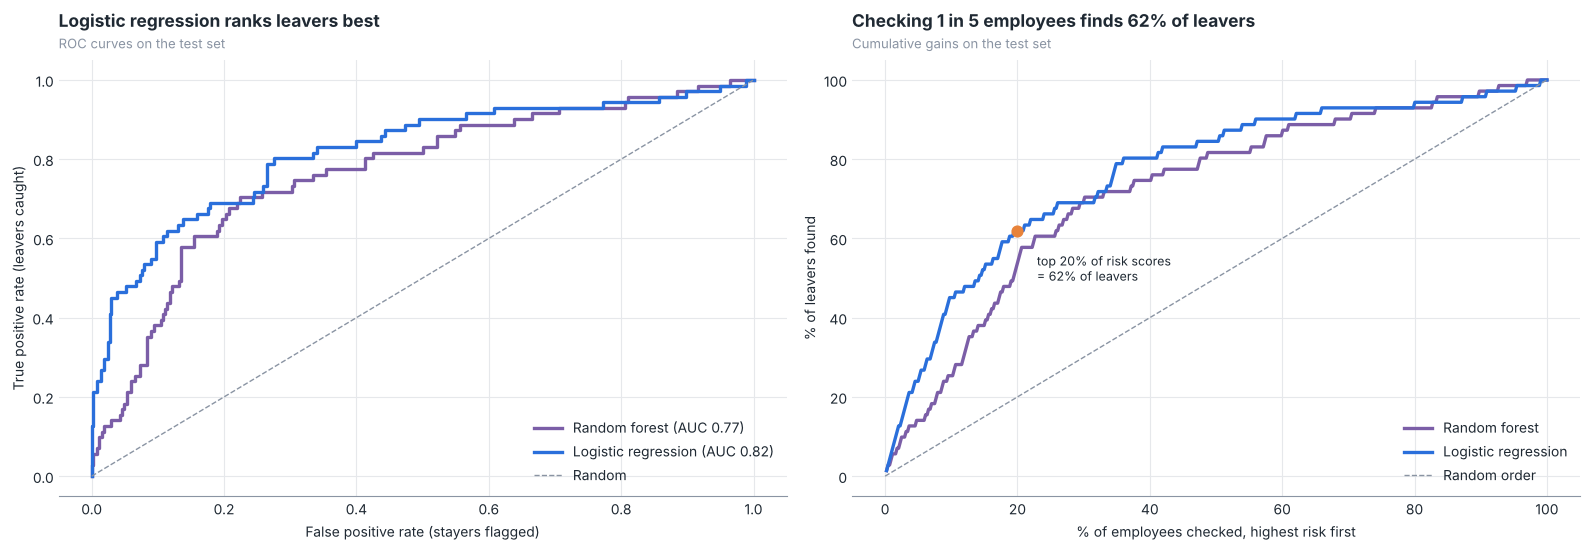

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.6))
style = {'Random forest': (PURPLE, '-'), 'Logistic regression': (BLUE, '-')}
for name, (color, ls) in style.items():
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    ax[0].plot(fpr, tpr, color=color, lw=2.4, ls=ls, label=f'{name} (AUC {results.loc[name, "test AUC"]:.2f})')
    looked, found = gains_curve(y_test.values, test_proba[name])
    ax[1].plot(looked * 100, found * 100, color=color, lw=2.4, label=name)
ax[0].plot([0, 1], [0, 1], color=MUTED, ls='--', lw=1, label='Random')
ax[0].set_xlabel('False positive rate (stayers flagged)')
ax[0].set_ylabel('True positive rate (leavers caught)')
ax[0].legend(loc='lower right')
titles(ax[0], f'{best_name} ranks leavers best', 'ROC curves on the test set')

ax[1].plot([0, 100], [0, 100], color=MUTED, ls='--', lw=1, label='Random order')
looked, found = gains_curve(y_test.values, test_proba[best_name])
top20 = found[int(np.ceil(0.2 * len(found))) - 1]
ax[1].scatter([20], [top20 * 100], color=LEFT, s=60, zorder=3)
ax[1].annotate(f'top 20% of risk scores\n= {pct(top20, 0)} of leavers', (20, top20 * 100), xytext=(14, -36), textcoords='offset points', fontsize=9)
ax[1].set_xlabel('% of employees checked, highest risk first')
ax[1].set_ylabel('% of leavers found')
ax[1].legend(loc='lower right')
titles(ax[1], f'Checking 1 in 5 employees finds {pct(top20, 0)} of leavers', 'Cumulative gains on the test set')
plt.tight_layout()
show(fig, 'fig09_model_comparison')

base_acc = results.loc['Baseline: always "stays"', 'test accuracy at 0.5']
callout(f'**{best_name}** has the best cross-validated AUC ({results.loc[best_name, "CV AUC (mean)"]:.2f}) and test AUC '
        f'**{results.loc[best_name, "test AUC"]:.2f}**; the random forest reaches {results.loc["Random forest", "test AUC"]:.2f}. '
        f'Ranking employees by risk, the top 20% contain **{pct(top20, 0)}** of all leavers in the test set. '
        f'Accuracy hides all of this: always predicting "stays" scores **{pct(base_acc)}**.')

In [19]:
# Parameters
TARGET_RECALL = 0.60      # share of leavers HR wants to catch

# Choose the threshold on out-of-fold training predictions, then apply it once to the test set
oof = cross_val_predict(best, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
THRESHOLD = threshold_for_recall(y_train.values, oof, TARGET_RECALL)
proba_best = test_proba[best_name]
at_05, at_t = metrics_at(y_test.values, proba_best, 0.5), metrics_at(y_test.values, proba_best, THRESHOLD)
operating = pd.DataFrame({'threshold 0.5': at_05, f'threshold {THRESHOLD:.2f} (chosen)': at_t}).T
operating[['threshold', 'flagged', 'tp', 'fp', 'fn', 'precision', 'recall', 'accuracy']].round(3)

,threshold,flagged,tp,fp,fn,precision,recall,accuracy
threshold 0.5,0.500,137.000,49.000,88.000,22.000,0.358,0.690,0.751
threshold 0.66 (chosen),0.660,74.000,39.000,35.000,32.000,0.527,0.549,0.848


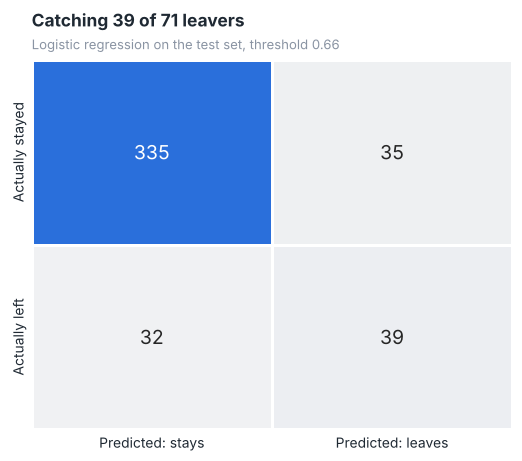

In [20]:
cm = np.array([[at_t['tn'], at_t['fp']], [at_t['fn'], at_t['tp']]])
fig, ax = plt.subplots(figsize=(6.2, 4.8))
sns.heatmap(cm, annot=True, fmt='d', cmap=sns.light_palette(BLUE, as_cmap=True), cbar=False, linewidths=2, linecolor='white',
            xticklabels=['Predicted: stays', 'Predicted: leaves'], yticklabels=['Actually stayed', 'Actually left'],
            annot_kws={'fontsize': 14}, ax=ax)
ax.grid(False)
titles(ax, f'Catching {at_t["tp"]} of {at_t["tp"] + at_t["fn"]} leavers', f'{best_name} on the test set, threshold {THRESHOLD:.2f}')
show(fig, 'fig10_confusion_matrix')

callout(f'At the chosen threshold the model flags **{at_t["flagged"]}** of {len(y_test)} test employees and catches **{at_t["tp"]} of {at_t["tp"] + at_t["fn"]} leavers '
        f'(recall {pct(at_t["recall"], 0)})**; **{pct(at_t["precision"], 0)}** of flagged people actually leave (precision), against {pct(y_test.mean(), 0)} if picked at random. '
        f'The default 0.5 threshold would catch {at_05["tp"]} leavers but flag {at_05["flagged"]} people (precision {pct(at_05["precision"], 0)}); '
        'the threshold is a trade-off between missing leavers and spending time on people who would have stayed. '
        'In practice the output is a short list for stay interviews, not an automatic decision about individuals.')

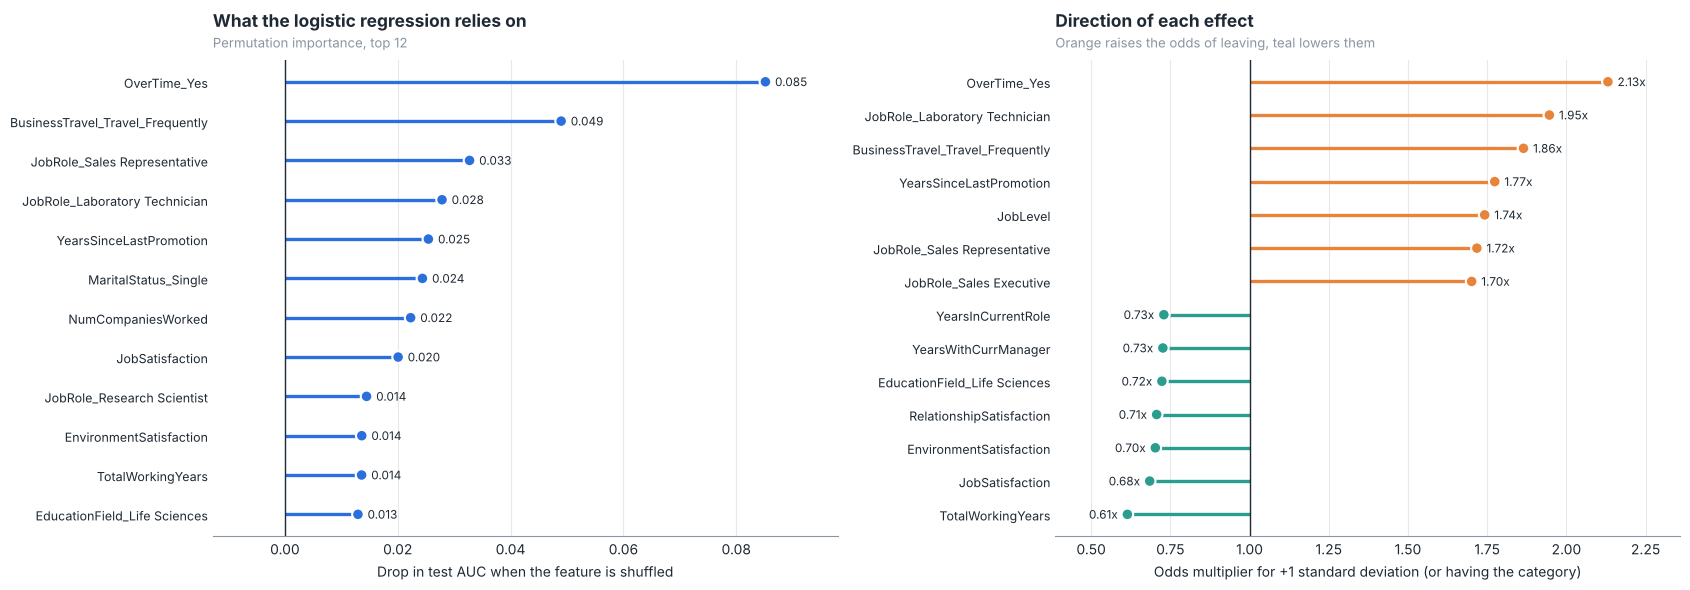

In [21]:
perm = permutation_importance(best, X_test, y_test, scoring='roc_auc', n_repeats=20, random_state=42)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(17, 6))
lollipop(ax[0], importance.head(12), center=0, fmt='{:.3f}')
ax[0].set_xlabel('Drop in test AUC when the feature is shuffled')
titles(ax[0], f'What the {best_name.lower()} relies on', 'Permutation importance, top 12')

if best_name == 'Logistic regression':
    coef = pd.Series(best[-1].coef_[0], index=X.columns)
    shown = pd.concat([coef.nlargest(7), coef.nsmallest(7)]).sort_values(ascending=False)
    lollipop(ax[1], np.exp(shown), center=1, fmt='{:.2f}x', colors=[LEFT if v > 0 else STAYED for v in shown])
    ax[1].set_xlabel('Odds multiplier for +1 standard deviation (or having the category)')
    titles(ax[1], 'Direction of each effect', 'Orange raises the odds of leaving, teal lowers them')
plt.tight_layout()
show(fig, 'fig11_feature_importance')

rf_imp = pd.Series(models['Random forest'].feature_importances_, index=X.columns).rank(ascending=False)
callout('The model mainly uses ' + ', '.join(f'**{f}**' for f in importance.head(5).index) +
        '. These are associations the model exploits, not proven causes.')
callout(f'The random forest\'s built-in importance ranks `DailyRate` **#{int(rf_imp["DailyRate"])}**, although its correlation with leaving is only '
        f'{with_left["DailyRate"]:+.2f}. Built-in tree importance favours features with many distinct values, which is why permutation importance on the test set is used here.', 'caution')

<a id="s10"></a>
## 💼 10. Business case

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>Recommendations are more convincing with numbers, but only if the assumptions are visible. Each scenario below states its inputs in the parameter cell; the prevented departures come from the data where possible.</div>

In [22]:
# Parameters: assumptions, not facts. Change them to test the business case.
OT_SHARE_REMOVED = 0.40        # share of overtime workers moved to standard hours
OT_PROGRAM_COST = 400_000      # extra headcount and monitoring
PAY_TARGETED_LEAVERS = 30      # leavers in high-risk, low-pay roles the pay programme targets
PAY_PREVENTION = 0.35          # share of those it prevents
PAY_PROGRAM_COST = 850_000     # salary adjustments and bonuses
CAREER_PREVENTION = 0.25       # share of early-career leavers (0-5 years) a mentoring programme prevents
CAREER_PROGRAM_COST = 380_000  # mentoring, training, stipends
INTERVENTION_SUCCESS = 0.30    # share of flagged-and-correctly-identified leavers kept by a stay interview
MODEL_PROGRAM_COST = 150_000   # deploying the risk score and training managers

ot_n = int((data['OverTime'] == 'Yes').sum())
ot_gap = ot.loc['Yes', 'rate'] - ot.loc['No', 'rate']
early = data['TenureBand'].isin(['0-2 yrs', '3-5 yrs'])
early_left = int(data.loc[early, 'left'].sum())

scenarios = pd.DataFrame({
    'Reduce overtime': {'prevented': OT_SHARE_REMOVED * ot_n * ot_gap, 'cost': OT_PROGRAM_COST,
                        'logic': f'{pct(OT_SHARE_REMOVED, 0)} of {ot_n} overtime workers drop to the no-overtime rate (−{ot_gap * 100:.1f} pts)'},
    'Targeted pay rises': {'prevented': PAY_TARGETED_LEAVERS * PAY_PREVENTION, 'cost': PAY_PROGRAM_COST,
                           'logic': f'{pct(PAY_PREVENTION, 0)} of {PAY_TARGETED_LEAVERS} targeted leavers stay'},
    'Early-career programme': {'prevented': early_left * CAREER_PREVENTION, 'cost': CAREER_PROGRAM_COST,
                               'logic': f'{pct(CAREER_PREVENTION, 0)} of {early_left} leavers with 0-5 years tenure stay'},
    'Risk score + stay interviews': {'prevented': n_left * at_t['recall'] * INTERVENTION_SUCCESS, 'cost': MODEL_PROGRAM_COST,
                                     'logic': f'model catches {pct(at_t["recall"], 0)} of leavers, {pct(INTERVENTION_SUCCESS, 0)} of those are kept'},
}).T
scenarios['prevented'] = scenarios['prevented'].astype(float).round(0)
scenarios['cost'] = scenarios['cost'].astype(float)
scenarios['savings'] = scenarios['prevented'] * COST_PER_LEAVER
scenarios['net'] = scenarios['savings'] - scenarios['cost']
scenarios['ROI'] = scenarios['net'] / scenarios['cost']
money = '${:,.0f}'.format
(scenarios[['logic', 'prevented', 'savings', 'cost', 'net', 'ROI']]
 .assign(prevented=lambda t: t['prevented'].astype(int), savings=lambda t: t['savings'].map(money),
         cost=lambda t: t['cost'].map(money), net=lambda t: t['net'].map(money), ROI=lambda t: t['ROI'].map('{:+.0%}'.format)))

,logic,prevented,savings,cost,net,ROI
Reduce overtime,40% of 416 overtime workers drop to the no-overtime rate (−20.1 pts),33,"$1,650,000","$400,000","$1,250,000",+312%
Targeted pay rises,35% of 30 targeted leavers stay,10,"$500,000","$850,000","$-350,000",-41%
Early-career programme,25% of 162 leavers with 0-5 years tenure stay,40,"$2,000,000","$380,000","$1,620,000",+426%
Risk score + stay interviews,"model catches 55% of leavers, 30% of those are kept",39,"$1,950,000","$150,000","$1,800,000",+1200%


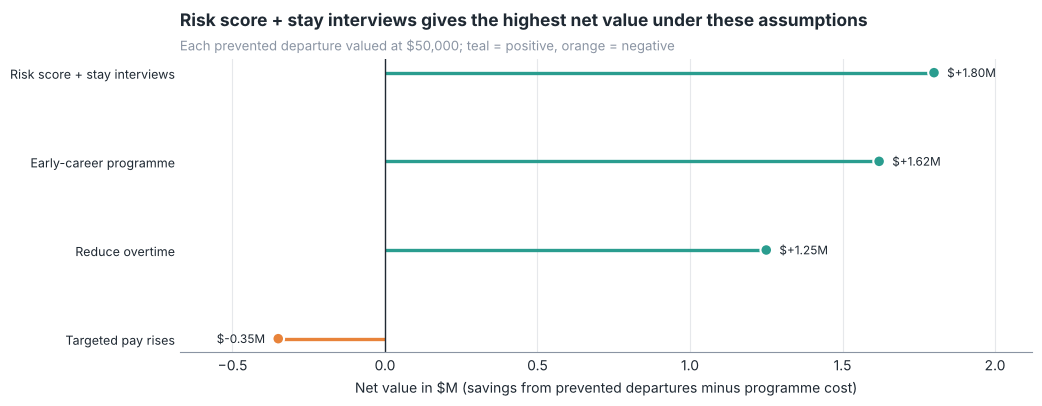

In [23]:
net = scenarios['net'].astype(float).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 3.8))
lollipop(ax, net / 1e6, center=0, fmt='${:+.2f}M', colors=[STAYED if v > 0 else LEFT for v in net])
ax.set_xlabel('Net value in $M (savings from prevented departures minus programme cost)')
titles(ax, f'{net.index[0]} gives the highest net value under these assumptions',
       f'Each prevented departure valued at ${COST_PER_LEAVER:,}; teal = positive, orange = negative')
show(fig, 'fig12_business_case')

overlap = int((early & (data['OverTime'] == 'Yes') & (data['left'] == 1)).sum())
pay = scenarios.loc['Targeted pay rises']
callout(f'Under these assumptions **{net.index[0]}** (${net.iloc[0] / 1e6:+.2f}M) and **{net.index[1]}** (${net.iloc[1] / 1e6:+.2f}M) give the highest net value; '
        f'{(net > 0).sum()} of {len(net)} options pay back their cost. Targeted pay rises come out at '
        f'**{pay["ROI"]:+.0%}** on replacement cost alone ({pay["prevented"]:.0f} departures prevented for ${pay["cost"]:,.0f}); '
        'they may still be right for fairness or market reasons, but the retention case alone does not carry them.')
callout(f'The scenarios overlap ({overlap} leavers are both early-career and on overtime), so their savings are not additive. '
        'Prevention rates and costs are assumptions, not estimates from this data, and the data has no time dimension, so "per year" figures are not possible.', 'caution')

<a id="s11"></a>
## 🏁 11. Findings, roadmap and limits

### 📊 What the data says
1. ⏰ **Overtime is the biggest lever.** 30.5% attrition with overtime vs 10.4% without (2.9x, the largest effect size of all factors).
2. 🎯 **Risk is concentrated** in Sales Representatives (39.8%), Laboratory Technicians (23.9%), the first two years of tenure (29.8%), under-25s (35.8%) and the lowest pay band (28.6%).
3. 💰 **Pay, age and experience move together.** Leavers have a median income of $3,202 vs $5,204, are younger and have shorter tenure; these are overlapping signals of being early in a career.
4. 😟 **Dissatisfaction matters at the bottom of the scale.** The lowest job satisfaction, environment satisfaction and work-life balance scores have clearly higher attrition; above that, differences are small.
5. 🤖 **Risk can be ranked, not predicted with certainty.** The logistic regression reaches test AUC 0.82; at a threshold aimed at catching 60% of leavers it catches 55% with a precision of 53%.

### 🗺️ Suggested roadmap
| Phase | Actions | Measure of success |
|---|---|---|
| Months 1-3 | Overtime dashboard per department; first risk-score list for HR business partners; stay interviews for the top-risk group | Overtime share falls from 28.3%; every flagged employee has a conversation |
| Months 4-6 | Mentoring and clear career steps for employees in their first 2 years; review pay for Sales Representatives and Laboratory Technicians | First-2-year attrition falls from 29.8% |
| Months 7-12 | Retrain the model on new data with dates; track results against a comparison group | Overall attrition below its current 16.1% |

### 📈 KPIs to track
| Indicator | Current value | Type |
|---|---|---|
| Overtime share of employees | 28.3% | Leading |
| Share of employees with job satisfaction 1 | 19.7% | Leading |
| Attrition, first 2 years of tenure | 29.8% | Lagging |
| Attrition, Sales Representatives | 39.8% | Lagging |
| Overall attrition | 16.1% | Lagging |

### ⚠️ Limitations
- **Fictional data.** The dataset was created by IBM data scientists for teaching; patterns may not hold in a real organisation.
- **Snapshot, no dates.** Rates are shares of one workforce, not annual turnover, and the model cannot say *when* someone will leave.
- **Association, not cause.** Overtime, pay and satisfaction go with leaving; this data cannot prove that changing them keeps people.
- **Small groups.** Some roles and age bands have fewer than 100 people, so their rates are uncertain (see the intervals).
- **Business case = assumptions.** Costs and prevention rates are illustrative inputs in a parameter cell, not measured effects.
- **Fairness.** A risk score must not be used for decisions about individuals without human review; features such as age, gender and marital status need care.

### 🚀 Next steps
- Collect exit dates and model *time to leaving* (survival analysis) instead of a yes/no flag.
- Test retention measures as a pilot with a comparison group to measure their real effect.
- Check the model's error rates per gender and age group before any use.

In [24]:
# Save the cleaned data with segments and risk scores for the test set
os.makedirs('output', exist_ok=True)
data.drop(columns=['status']).to_csv('output/attrition_clean.csv', index=False)
risk = X_test.assign(left=y_test, risk_score=proba_best, flagged=proba_best >= THRESHOLD)
risk[['left', 'risk_score', 'flagged']].to_csv('output/test_risk_scores.csv')
scenarios.to_csv('output/business_case.csv')
import shutil
from hr_utils import FIG_DIR
shutil.make_archive('output/figures', 'zip', FIG_DIR)
callout(f'Saved `output/attrition_clean.csv`, `output/test_risk_scores.csv`, `output/business_case.csv` and '
        f'{len(glob.glob(os.path.join(FIG_DIR, "*.png")))} charts in `{FIG_DIR}` (also zipped as `output/figures.zip`).', 'result')